Olá!

Meu nome é **Gabriel Aguiar** e serei o revisor do seu projeto hoje.

Quando identificar um erro pela primeira vez, apenas vou apontá-lo para que você mesmo possa encontrá-lo e corrigi-lo. Ao longo do notebook também farei observações de melhoria e comentários sobre suas análises — meu objetivo é prepará-lo(a) para trabalhar como **Data Analyst** no mercado real.

Se não conseguir identificar o erro, na próxima iteração darei uma dica mais precisa com exemplos práticos. Estou aberto a feedbacks e discussões.

**Por favor, não mova, modifique ou exclua meus comentários.**

Você encontrará meus comentários em caixas coloridas:

<div class="alert alert-block alert-success">
<b>Comentário do revisor (Gabriel Aguiar):</b> <a class="tocSkip"></a>
Sucesso. Tudo foi feito corretamente.
</div>

<div class="alert alert-block alert-warning">
<b>Comentário do revisor (Gabriel Aguiar):</b> <a class="tocSkip"></a>
Atenção. Sugestão ou observação de melhoria.
</div>

<div class="alert alert-block alert-danger">
<b>Comentário do revisor (Gabriel Aguiar):</b> <a class="tocSkip"></a>
Precisa de correção. O projeto não pode ser aceito com comentários em vermelho abertos.
</div>

Você pode me responder usando:

<div class="alert alert-block alert-info">
<b>Resposta do Aluno.</b> <a class="tocSkip"></a>
</div>


<div class="alert alert-block alert-success">
<b>Comentário geral do revisor v1 (Gabriel Aguiar):</b> <a class="tocSkip"></a>

Parabéns, seu projeto está aprovado! Este é um projeto de storytelling com dados, sem template pré-definido, e você organizou tudo muito bem: seções numeradas, observações após cada análise, e uma camada extra de "implicações para o negócio" que conecta cada número à decisão de abrir a cafeteria com garçons robôs. A extração de nomes de rua via regex (removendo prefixos direcionais e complementos como "ste"/"unit") é mais robusta que a abordagem mais simples de apenas dividir a string no primeiro espaço, e o jointplot para caracterizar as redes (número de locais x média de assentos) foi uma escolha visual mais rica do que um histograma simples.

Deixei vários comentários verdes destacando os pontos mais fortes da análise. Fique à vontade para avançar para o próximo sprint. Qualquer dúvida, conte comigo. Até breve!
</div>


# Projeto: Mercado de restauração em L.A.

## 1. Importação das bibliotecas e carregamento dos dados

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Carregamento dos dados e exploração inicial 

In [19]:
df = pd.read_csv('/datasets/rest_data_us_upd.csv')
df.info()
print(df.head(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9651 entries, 0 to 9650
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           9651 non-null   int64 
 1   object_name  9651 non-null   object
 2   address      9651 non-null   object
 3   chain        9648 non-null   object
 4   object_type  9651 non-null   object
 5   number       9651 non-null   int64 
dtypes: int64(2), object(4)
memory usage: 452.5+ KB
      id          object_name                          address  chain  \
0  11786  HABITAT COFFEE SHOP           3708 N EAGLE ROCK BLVD  False   
1  11787             REILLY'S                100 WORLD WAY 120  False   
2  11788       STREET CHURROS          6801 HOLLYWOOD BLVD 253  False   
3  11789    TRINITI ECHO PARK               1814 W SUNSET BLVD  False   
4  11790               POLLEN               2100 ECHO PARK AVE  False   
5  11791       THE SPOT GRILL              10004 NATIONAL BLVD  False   
6  

In [20]:
print(df.isna().sum())

id             0
object_name    0
address        0
chain          3
object_type    0
number         0
dtype: int64


In [21]:
print(df.duplicated().sum())

0


#### Observações
* O conjunto de dados contém 9.651 linhas e 6 colunas.
*  Foram identificados apenas 3 valores ausentes na coluna 'chain' (0.03% do total). As restantes colunas não apresentam dados em falta. Por ser uma percentagem insignificante em relação ao tamanho total da amostra, optaremos por eliminar estas 3 linhas na fase de limpeza, visto que a sua remoção não afeta a representatividade dos dados nem introduz qualquer viés analítico.
* A coluna 'chain' está codificada como 'object' (texto) em vez de booleano (True/False), exigindo conversão.
* Não existem duplicados exatos, mas é necessário padronizar os textos ('object_name', 'address') em minúsculas e sem espaços para verificar e tratar possíveis duplicados implícitos.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Gabriel Aguiar):</b> <a class="tocSkip"></a>

Boa decisão documentada: em vez de simplesmente rodar um `dropna()` genérico, você quantificou o impacto (0,03% da amostra) antes de decidir remover as 3 linhas sem `chain`. Esse tipo de justificativa evita perder dado bom por engano e deixa claro pra quem lê o notebook por que a decisão foi tomada.
</div>


## 3.Limpeza e pré-processamento dos dados

In [22]:
# Padronização de todas as colunas de texto (minúsculas e remoção de espaços extras
df['object_name'] = df['object_name'].str.lower().str.strip()
df['address'] = df['address'].str.lower().str.strip()
df['object_type'] = df['object_type'].str.lower().str.strip()

In [23]:
# Eliminação dos valores ausentes na coluna 'chain' 
df = df.dropna(subset=['chain']).reset_index(drop=True)

In [24]:
# Conversão da coluna 'chain' para tipo booleano
df['chain'] = df['chain'].astype(bool)

In [25]:
# Confirmação da limpeza
df.info()
print(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9648 entries, 0 to 9647
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   id           9648 non-null   int64 
 1   object_name  9648 non-null   object
 2   address      9648 non-null   object
 3   chain        9648 non-null   bool  
 4   object_type  9648 non-null   object
 5   number       9648 non-null   int64 
dtypes: bool(1), int64(2), object(3)
memory usage: 386.4+ KB
      id          object_name                  address  chain object_type  \
0  11786  habitat coffee shop   3708 n eagle rock blvd  False        cafe   
1  11787             reilly's        100 world way 120  False  restaurant   
2  11788       street churros  6801 hollywood blvd 253  False   fast food   
3  11789    triniti echo park       1814 w sunset blvd  False  restaurant   
4  11790               pollen       2100 echo park ave  False  restaurant   

   number  
0      26  
1       9  
2     

## 4. Análise dos dados

### 4.1 Proporção dos Tipos de Estabelecimentos

--- Distribuição por Tipo de Estabelecimento ---


,object_type,count,percentage
0,restaurant,7253,75.18%
1,fast food,1066,11.05%
2,cafe,435,4.51%
3,pizza,319,3.31%
4,bar,292,3.03%
5,bakery,283,2.93%


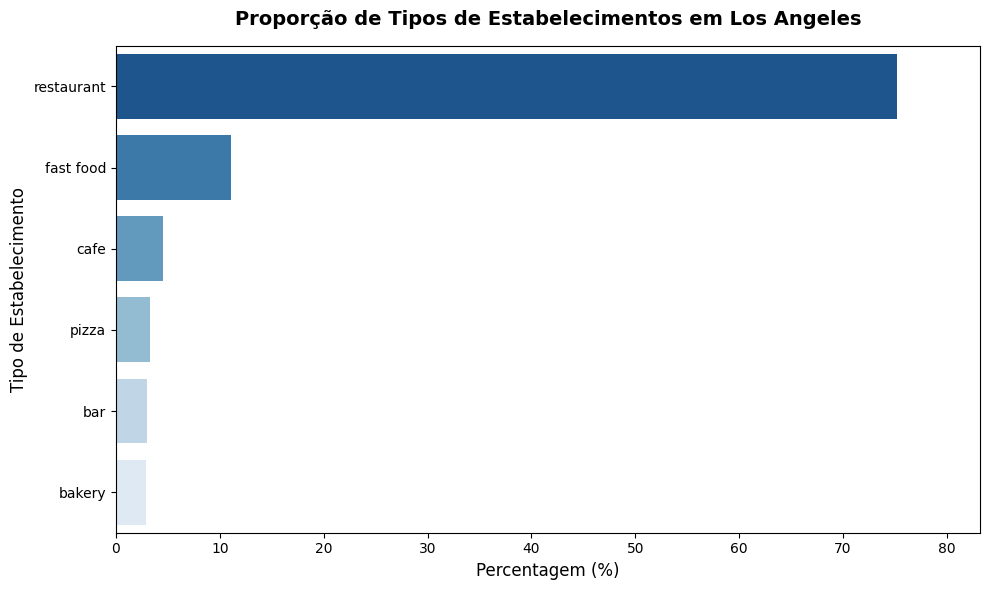

In [26]:
# Contagem absoluta e percentagem de cada tipo de estabelecimento
type_counts = df['object_type'].value_counts().reset_index()
type_counts.columns = ['object_type', 'count']
type_counts['percentage'] = (type_counts['count'] / len(df)) * 100

# Tabela com as proporções
print("--- Distribuição por Tipo de Estabelecimento ---")
display(type_counts.style.format({'percentage': '{:.2f}%'}))

# Gráfico de barras com a seaborn
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=type_counts,
    x='percentage',
    y='object_type',
    palette='Blues_r'
)

plt.title('Proporção de Tipos de Estabelecimentos em Los Angeles', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Percentagem (%)', fontsize=12)
plt.ylabel('Tipo de Estabelecimento', fontsize=12)
plt.xlim(0, max(type_counts['percentage']) + 8) # Espaço extra para o texto das percentagens
plt.tight_layout()
plt.show()

#### Observações
* Os restaurantes representam a grande maioria do mercado de restauração em Los Angeles, cobrindo 75.18% (7.253 estabelecimentos) de toda a amostra.
* O segundo maior tipo é o fast food, representando 11.05% (1.066 locais), refletindo a forte cultura de refeições rápidas na cidade.
* As cafeterias surgem na 3.ª posição, com 4.51% (435 estabelecimentos). Os restantes formatos (pizzarias, bares e padarias) cobrem individualmente cerca de 3% do mercado.

##### Implicações para o Nosso Negócio:
1. Embora os restaurantes dominem a restauração em LA, o segmento específico de café representa um mercado de nicho relevante (435 estabelecimentos). 
2. Abrir uma cafeteria num mercado onde a maioria são restaurantes tradicionais permite definir um conceito claro e focado (bebidas, snacks e refeições leves). O fator de novidade dos garçons robôs terá um impacto visual e de marketing muito superior num ambiente de café do que ao tentar competir diretamente com os 7.253 restaurantes convencionais.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Gabriel Aguiar):</b> <a class="tocSkip"></a>

Boa análise, com números específicos (75,18% restaurantes, 11,05% fast food, 4,51% cafés) em vez de afirmações genéricas. A leitura de que o nicho de cafeterias, mesmo sendo pequeno, é relevante justamente por ser um espaço menos disputado que o mercado de restaurantes tradicionais, é o tipo de raciocínio de negócio que se espera de um projeto de storytelling.
</div>


### 4.2 Proporção de estabelecimentos de rede e não rede

--- Distribuição de Estabelecimentos de Rede vs. Independentes ---


,chain_label,count,percentage
0,Independente (Non-Chain),5972,61.90%
1,Rede (Chain),3676,38.10%


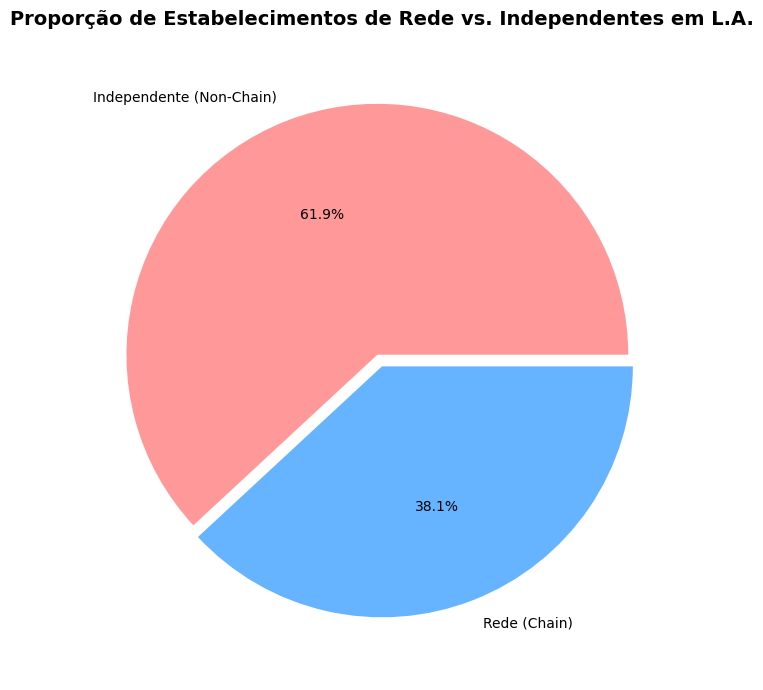

In [27]:
# Contagem e percentagem de estabelecimentos de rede e não rede
chain_counts = df['chain'].value_counts().reset_index()
chain_counts.columns = ['chain', 'count']

# Mapear True/False para nomes mais explícitos
chain_counts['chain_label'] = chain_counts['chain'].map({True: 'Rede (Chain)', False: 'Independente (Non-Chain)'})
chain_counts['percentage'] = (chain_counts['count'] / len(df)) * 100

# Tabela de frequências
print("--- Distribuição de Estabelecimentos de Rede vs. Independentes ---")
display(chain_counts[['chain_label', 'count', 'percentage']].style.format({'percentage': '{:.2f}%'}))

# Gráfico circular para melhor representar as proporções
plt.figure(figsize=(7, 7))
plt.pie(
    chain_counts['count'], 
    labels=chain_counts['chain_label'], 
    autopct='%1.1f%%', 
    colors=['#ff9999','#66b3ff'],
    explode=(0.05, 0), 
)

plt.title('Proporção de Estabelecimentos de Rede vs. Independentes em L.A.', fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

#### Observações
* A maioria dos estabelecimentos de restauração em Los Angeles é de propriedade independente (61.90%, representando 5.972 locais).
* Os estabelecimentos integrados em redes representam 38.10% do mercado (3.676 locais).

##### Implicações para o Nosso Negócio:
1. O facto de quase 62% do mercado ser composto por estabelecimentos independentes mostra que a restauração em Los Angeles acolhe bem conceitos únicos e não padronizados.
2. Como a maioria do mercado não está dominada por grandes redes com padrões rígidos, a nossa cafeteria independente com garçons robôs encontrará um público habituado a frequentar locais independentes e recetivo a novos conceitos.
3. A fatia expressiva de 38.10% detida por redes prova que o mercado de Los Angeles tem maturidade e capacidade de escala para que, no futuro, o nosso conceito de robôs seja expandido sob a forma de uma rede.

### 4.3 Tipos de estabelecimentos típicos para redes

--- Proporção de Redes por Tipo de Estabelecimento ---


,object_type,total_count,chain_count,chain_percentage
0,bakery,283,283,100.00%
1,cafe,435,266,61.15%
2,fast food,1066,605,56.75%
3,pizza,319,153,47.96%
4,restaurant,7253,2292,31.60%
5,bar,292,77,26.37%


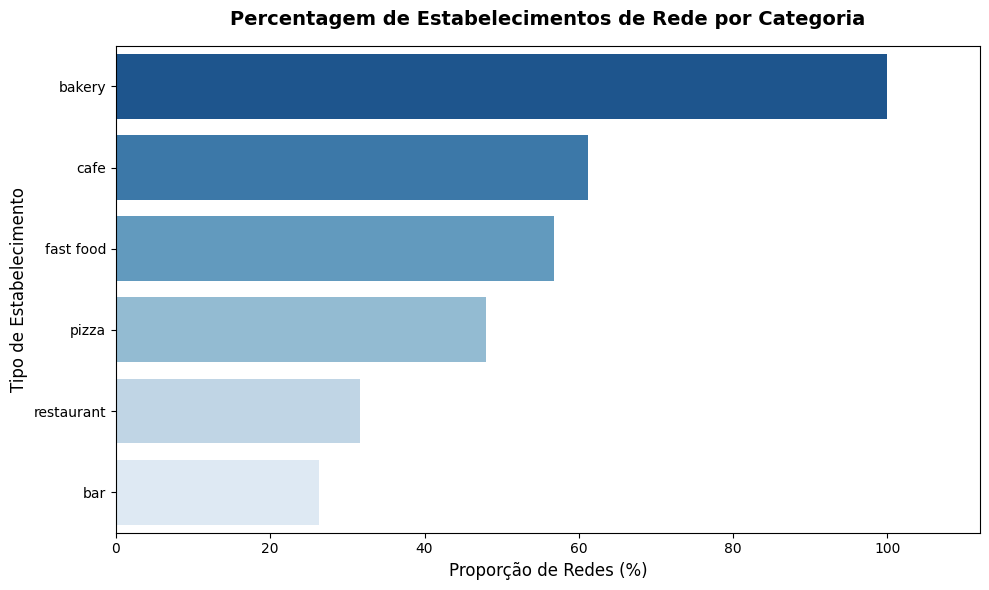

In [28]:
# Agrupamento por 'object_type' e cálculo da percentagem de redes (chain == True)
chain_by_type = df.groupby('object_type')['chain'].agg(
    total_count='count',
    chain_count='sum'
).reset_index()


chain_by_type['chain_percentage'] = (chain_by_type['chain_count'] / chain_by_type['total_count']) * 100
chain_by_type = chain_by_type.sort_values(by='chain_percentage', ascending=False).reset_index(drop=True)

# Tabela com os resultados
print("--- Proporção de Redes por Tipo de Estabelecimento ---")
display(chain_by_type.style.format({'chain_percentage': '{:.2f}%'}))



# Gráfico de barras com Seaborn
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=chain_by_type,
    x='chain_percentage',
    y='object_type',
    palette='Blues_r'
)

plt.title('Percentagem de Estabelecimentos de Rede por Categoria', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Proporção de Redes (%)', fontsize=12)
plt.ylabel('Tipo de Estabelecimento', fontsize=12)
plt.xlim(0, max(chain_by_type['chain_percentage']) + 12)
plt.tight_layout()
plt.show()

#### Observações
* As padarias apresentam uma taxa de 100% de redes (283 estabelecimentos), sendo um segmento totalmente dominado por marcas consolidadas e cadeias comerciais.
* Os cafés ocupam a 2.ª posição, com 61.15% (266 locais) operados sob a forma de rede. 
* Os estabelecimentos de Fast Food e Pizzarias apresentam também elevadas taxas de expansão em rede, com 56.75% e 47.96%, respetivamente.
* Os restaurantes e bares são os formatos menos suscetíveis ao modelo de rede, com apenas 31.60% dos restaurantes e 26.37% dos bares associados a cadeias.

##### Implicações para o nosso negócio
1. O facto de mais de 61% das cafeterias em L.A. funcionarem como rede prova que o formato de café/cafeteria é altamente padronizável e replicável.
2. Os investidores podem constatar que, embora o nosso projeto comece com uma unidade piloto independente, o segmento de cafeterias em Los Angeles tem um histórico comprovado de sucesso na transição de conceitos locais para redes.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Gabriel Aguiar):</b> <a class="tocSkip"></a>

Boa leitura dos dados: identificar que padarias e cafés são os tipos mais "padronizáveis" em rede (100% e 61%, respectivamente), enquanto restaurantes e bares são os menos, dá suporte direto à tese de que o conceito de cafeteria tem histórico de sucesso ao escalar para rede.
</div>


### 4.4 Caracterização das redes

--- Resumo Estatístico das Redes ---


,location_count,mean_seats
count,2733.000000,2733.000000
mean,1.345042,41.437569
std,1.489055,44.313242
min,1.000000,1.000000
25%,1.000000,14.000000
50%,1.000000,25.500000
75%,1.000000,45.000000
max,47.000000,229.000000


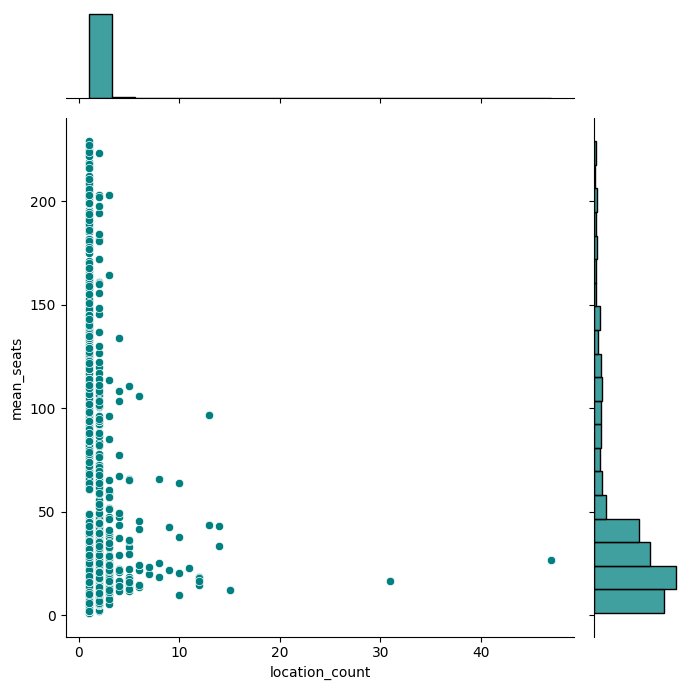

In [29]:
# Filtragem, obtendo apenas os estabelecimentos pertencentes a redes
chain_df = df[df['chain'] == True]

# Agrupamento por nome da rede e cálculo do número de locais e média de assentos
chain_summary = chain_df.groupby('object_name').agg(
    location_count=('id', 'count'),
    mean_seats=('number', 'mean')
).reset_index()

print("--- Resumo Estatístico das Redes ---")
display(chain_summary.describe())

# Jointplot com Seaborn (Scatter + Histogramas de Margem)
g = sns.jointplot(
    data=chain_summary,
    x='location_count',
    y='mean_seats',
    kind='scatter',
    height=7,
    space=0.2,
    color='teal',
    marginal_kws=dict(bins=20, fill=True)
)

plt.tight_layout()
plt.show()

#### Observações
*
 O histograma no topo do gráfico revela uma forte assimetria à direita: a esmagadora maioria das marcas opera com poucos estabelecimentos (mediana = 1, com $75\%$ das marcas até 1 local).
* O histograma lateral mostra que a capacidade de lugares está fortemente concentrada na faixa dos pequenos/médios estabelecimentos (mediana de 25.5 assentos, com $75\%$ das lojas a ter até 45 lugares).
* À medida que o número de estabelecimentos de uma marca aumenta (pontos mais à direita no gráfico), a média de assentos mantém-se quase sempre contida abaixo dos 50 lugares.

##### Implicações para o nosso negócio:
1. As redes em Los Angeles são predominantemente caracterizadas por muitos estabelecimentos com um pequeno a moderado número de assentos (tipicamente entre 15 e 45 lugares). 


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Gabriel Aguiar):</b> <a class="tocSkip"></a>

O jointplot foi uma escolha visual esperta aqui: além do scatter central (locais x assentos médios), os histogramas nas margens já respondem à pergunta da seção sem precisar de gráficos separados. A leitura da assimetria à direita (a maioria das marcas com poucos locais) está correta e é justamente o padrão típico desse tipo de dado.
</div>


### 4.5 Número Médio de Assentos por Tipo de Estabelecimento

--- Estatísticas do Número de Assentos por Tipo de Estabelecimento ---


,object_type,mean_seats,median_seats,std_seats,total_count
0,restaurant,48.05,29.0,50.51,7253
1,bar,44.77,28.5,46.79,292
2,fast food,31.84,21.0,35.09,1066
3,pizza,28.55,19.0,35.44,319
4,cafe,25.00,21.0,21.32,435
5,bakery,21.77,18.0,25.69,283


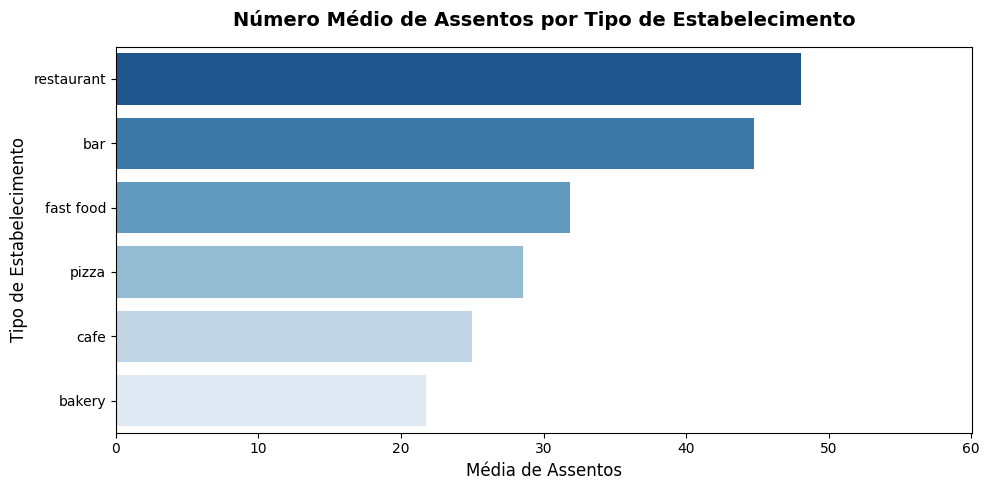

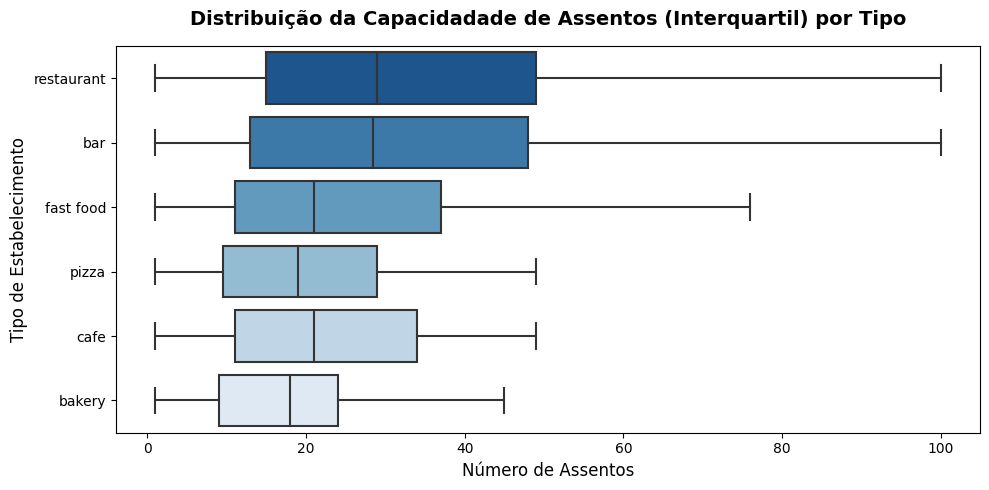

In [30]:
# Agrupamento por 'object_type' e cálculo da média, mediana, desvio padrão e contagem de assentos
seats_by_type = df.groupby('object_type')['number'].agg(
    mean_seats='mean',
    median_seats='median',
    std_seats='std',
    total_count='count'
).reset_index()

seats_by_type = seats_by_type.sort_values(by='mean_seats', ascending=False).reset_index(drop=True)

print("--- Estatísticas do Número de Assentos por Tipo de Estabelecimento ---")
display(seats_by_type.style.format({
    'mean_seats': '{:.2f}',
    'median_seats': '{:.1f}',
    'std_seats': '{:.2f}'
}))

# Gráfico 1: Média de Assentos por Tipo (Barplot)

plt.figure(figsize=(10, 5))
ax1 = sns.barplot(
    data=seats_by_type,
    x='mean_seats',
    y='object_type',
    palette='Blues_r'
)

plt.title('Número Médio de Assentos por Tipo de Estabelecimento', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Média de Assentos', fontsize=12)
plt.ylabel('Tipo de Estabelecimento', fontsize=12)
plt.xlim(0, max(seats_by_type['mean_seats']) + 12)
plt.tight_layout()
plt.show()


# Gráfico 2: Dispersão e Limites dos Assentos por Tipo (Boxplot sem valores extremos exagerados para visualização limpa)
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x='number',
    y='object_type',
    order=seats_by_type['object_type'],
    palette='Blues_r',
    showfliers=False 
)

plt.title('Distribuição da Capacidadade de Assentos (Interquartil) por Tipo', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Número de Assentos', fontsize=12)
plt.ylabel('Tipo de Estabelecimento', fontsize=12)
plt.tight_layout()
plt.show()

#### Observações
* Os restaurantes lideram o mercado com o maior número médio de assentos (48.05 lugares, mediana de 29.0), seguidos pelos bares com 44.77 lugares em média (mediana de 28.5).
* As cafeterias apresentam uma média de 25.00 assentos e uma mediana de 21.0 assentos, sendo o penúltimo segmento em dimensão de espaço (à frente apenas das padarias, com 21.77 assentos).
* O desvio padrão dos cafés ($21.32$) é substancialmente menor do que o dos restaurantes ($50.51$), o que indica que as cafeterias em Los Angeles seguem um padrão de dimensão bastante homogéneo e compacto.

##### Implicações para o nosso negócio:
1. A nossa cafeteria em Los Angeles deve ser projetada para uma capacidade entre 20 e 30 lugares sentados (alinhada com a média de 25 e mediana de 21 do mercado).

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Gabriel Aguiar):</b> <a class="tocSkip"></a>

Bom uso do desvio padrão aqui, não só da média: notar que o desvio padrão dos cafés (21,32) é bem menor que o dos restaurantes (50,51) é uma forma direta de mostrar que as cafeterias têm um padrão de tamanho mais homogêneo, o que reforça a recomendação de dimensionamento no fechamento do projeto.
</div>


### 4.6 Extração dos nomes das ruas

In [31]:
# Divisão do endereço no primeiro espaço
df['street'] = df['address'].str.split(' ', n=1).str[1]

# Extração do nome da rua 
df['street'] = df['address'].str.replace(r'^\d+\s+', '', regex=True) # Tira número inicial
df['street'] = df['street'].str.replace(r'^(n|s|e|w|north|south|east|west)\b\s+', '', regex=True)
df['street'] = df['street'].str.replace(r'\s+(ste|suite|unit|#|apt|fl|floor|spc|space)\b.*$', '', regex=True) # Tira complementos no fim
df['street'] = df['street'].str.strip()

# Confirmação
print("--- Validação da Extração do Nome das Ruas ---")
display(df[['address', 'street']].head(10))

--- Validação da Extração do Nome das Ruas ---


,address,street
0,3708 n eagle rock blvd,eagle rock blvd
1,100 world way 120,world way 120
2,6801 hollywood blvd 253,hollywood blvd 253
3,1814 w sunset blvd,sunset blvd
4,2100 echo park ave,echo park ave
5,10004 national blvd,national blvd
6,100 world way 126,world way 126
7,3500 w 6th st ste 226,6th st
8,3027 n san fernando rd unit 103,san fernando rd
9,3707 n cahuenga blvd,cahuenga blvd


<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Gabriel Aguiar):</b> <a class="tocSkip"></a>

Boa extração de rua: em vez de só dividir o endereço no primeiro espaço (o que deixaria "120" ou "253" sobrando de números de unidade, como dá pra ver nas linhas 1 e 2 antes do tratamento), você removeu o número inicial, os prefixos direcionais (N/S/E/W) e os complementos de unidade/andar com regex. É um tratamento mais cuidadoso do que o mínimo necessário para a tarefa.
</div>


### 4.7 Top 10 ruas com o maior número de restaurantes

--- Top 10 Ruas com Maior Número de Restaurantes em L.A. ---


,street,restaurant_count
0,sunset blvd,266
1,pico blvd,266
2,wilshire blvd,259
3,western ave,231
4,olympic blvd,221
5,figueroa st,201
6,vermont ave,197
7,3rd st,174
8,hollywood blvd,171
9,santa monica blvd,155


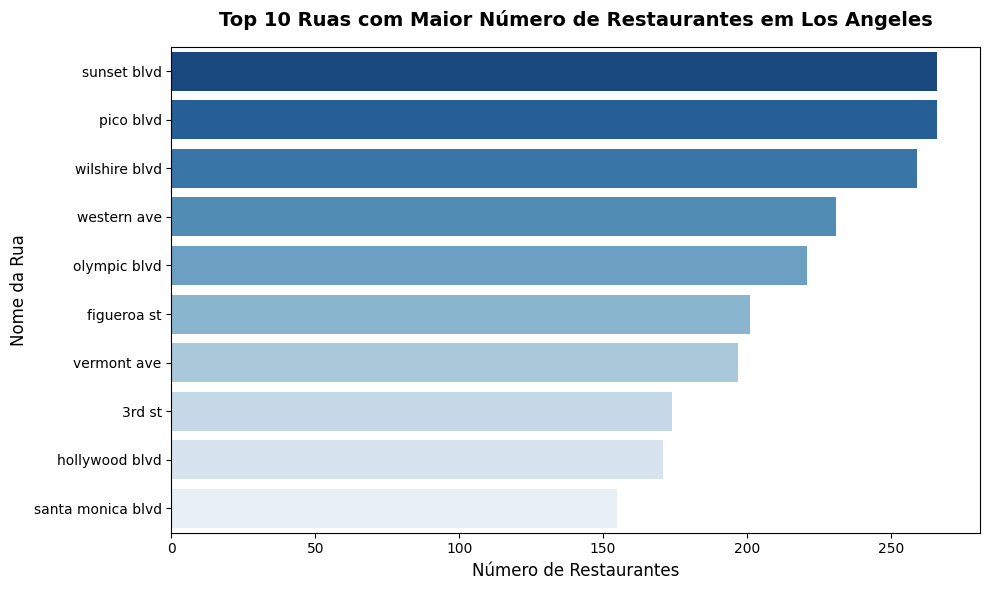

In [32]:
# Filtragem da categoria 'restaurant' e agrupamento por rua por rua
restaurants_df = df[df['object_type'] == 'restaurant']

top_10_streets = (
    restaurants_df.groupby('street')['id']
    .count()
    .reset_index(name='restaurant_count')
    .sort_values(by='restaurant_count', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

# Tabela com o Top 10 de ruas com mais restaurantes
print("--- Top 10 Ruas com Maior Número de Restaurantes em L.A. ---")
display(top_10_streets)

# Gráfico de barras horizontal com Seaborn
plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=top_10_streets,
    x='restaurant_count',
    y='street',
    palette='Blues_r'
)

plt.title('Top 10 Ruas com Maior Número de Restaurantes em Los Angeles', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Número de Restaurantes', fontsize=12)
plt.ylabel('Nome da Rua', fontsize=12)
plt.xlim(0, max(top_10_streets['restaurant_count']) + 15)
plt.tight_layout()
plt.show()

#### Observações
* As ruas Sunset Blvd (266 estabelecimentos), Pico Blvd (266) e Wilshire Blvd (259) lideram o mercado de Los Angeles como as ruas com maior densidade de restauração.
* As 10 principais ruas agregam mais de 2.100 restaurantes, refletindo zonas de elevado tráfego de peões e veículos, turismo intenso e forte densidade de escritórios e habitação.

##### Implicações para o nosso negócio:
1. Instalar a cafeteria piloto numa destas grandes avenidas (ex: Wilshire Blvd ou Sunset Blvd) garante exposição imediata a um elevado volume de potenciais clientes e curiosos pelo conceito inovador de robôs.
2. Contudo, nestas ruas, a concorrência é extremamente elevada e os custos de aluguer provavelmente serão mais altos.
3. Poderá ser interessante escolher uma localização adjacente ou num troço de elevado tráfego pedonal de uma destas vias principais. A inovação tecnológica dos robôs poderá funcionar como um fator de diferenciação para destacar a nossa cafeteria no meio da densa oferta gastronómica destas ruas.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Gabriel Aguiar):</b> <a class="tocSkip"></a>

Boa ponderação nas implicações de negócio: em vez de só recomendar "abrir na rua com mais restaurantes", você pesou o trade-off entre visibilidade e concorrência/custo de aluguel, e sugeriu uma alternativa (rua adjacente com bom fluxo). É uma leitura mais madura do dado do que simplesmente seguir o número mais alto.
</div>


### 4.8 Ruas com apenas um restaurante

In [33]:
# 1. Agrupamento dos restaurantes por rua e contagem da frequência
street_counts = (
    restaurants_df.groupby('street')['id']
    .count()
    .reset_index(name='restaurant_count')
)

# 2. Filtragem das ruas com apenas 1 restaurante
one_restaurant_streets = street_counts[street_counts['restaurant_count'] == 1]

# 3. Calcular totais e percentagens
total_streets = len(street_counts)
single_count = len(one_restaurant_streets)
single_percentage = (single_count / total_streets) * 100

# 4. Exibir resultados
print(f"--- Análise de Ruas com Apenas 1 Restaurante ---")
print(f"Total de ruas com restaurantes: {total_streets}")
print(f"Número de ruas com apenas 1 restaurante: {single_count}")
print(f"Proporção: {single_percentage:.2f}% do total de ruas com restaurantes")

--- Análise de Ruas com Apenas 1 Restaurante ---
Total de ruas com restaurantes: 1263
Número de ruas com apenas 1 restaurante: 895
Proporção: 70.86% do total de ruas com restaurantes


#### Observações
* A grande maioria das ruas em Los Angeles (70.86%) possui apenas um único restaurante. Isto demonstra que o setor da restauração não está concentrado exclusivamente em grandes corredores comerciais.
* A existência de tantas ruas com apenas um estabelecimento indica a presença de múltiplos focos de restauração local ou de bairro, onde a concorrência direta na mesma rua é mínima.
##### Implicações para o nosso negócio:
1. As ruas do top 10 têm elevado tráfego de clientes, mas exigem competir com marcas estabelecidas e suportar rendas/custos operacionais mais elevados.
2. As ruas com apenas um restaurante podem representar zonas residenciais ou de escritórios com procura não atendida, tornando-as atrativas para um conceito inovador (como o restaurante com garçons robôs), desde que haja fluxo pedonal ou facilidade de estacionamento/delivery.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Gabriel Aguiar):</b> <a class="tocSkip"></a>

Boa análise das ruas com apenas um restaurante: você não parou na constatação (70.86% das ruas), foi direto para o que isso significa para o negócio, distinguindo o trade-off entre abrir numa rua do top 10 (tráfego alto, mas concorrência e custo também) e uma rua de restaurante único (demanda potencialmente não atendida). Esse tipo de leitura orientada à decisão é exatamente o que se espera neste sprint.
</div>


### 4.9 Distribuição do número de assentos nas ruas com mais restaurantes

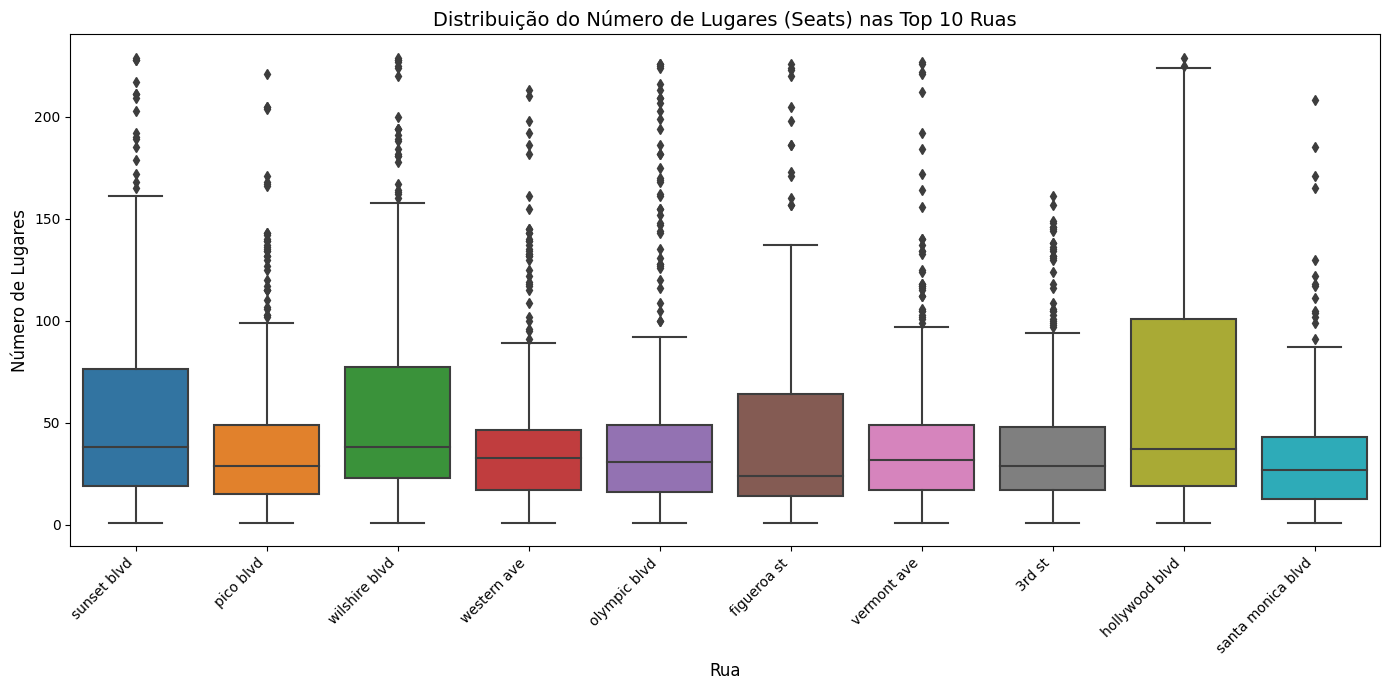

,count,mean,median,max
street,,,,
3rd st,174,44.626437,29,161
figueroa st,201,47.378109,24,226
hollywood blvd,171,61.935673,37,229
olympic blvd,221,53.176471,31,226
pico blvd,266,44.823308,29,221
santa monica blvd,155,35.548387,27,208
sunset blvd,266,53.808271,38,229
vermont ave,197,48.802030,32,227
western ave,231,45.225108,33,213


In [34]:
# Filtragem usando a variável criada na alínea 4.7
top_streets_df = restaurants_df[restaurants_df['street'].isin(top_10_streets['street'])]

# Gráfico de distribuição do número de lugares/assentos (Boxplot)
plt.figure(figsize=(14, 7))
sns.boxplot(
    data=top_streets_df,
    x='street',
    y='number',
    order=top_10_streets['street']
)

plt.title('Distribuição do Número de Lugares (Seats) nas Top 10 Ruas', fontsize=14)
plt.xlabel('Rua', fontsize=12)
plt.ylabel('Número de Lugares', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Estatísticas descritivas do número de lugares por rua
top_streets_df.groupby('street')['number'].agg(['count', 'mean', 'median', 'max'])

#### Observações
*Em todas as 10 ruas, a média é consideravelmente superior à mediana. Por exemplo, em Wilshire Blvd, a média é de ~60 lugares, mas a mediana é de 38 lugares. Isto acontece porque existem alguns estabelecimentos muito grandes (outliers com mais de 200 lugares) que "puxam" a média para cima.
* A mediana do número de lugares situa-se entre 24 e 38 assentos na maioria das vias. Isto indica que a oferta nestes grandes corredores é maioritariamente constituída por pequenos restaurantes, cafés e estabelecimentos de serviço rápido (*quick-service*).
* Hollywood Blvd (média de 61.9 lugares) e Wilshire Blvd (média de 59.5 lugares) concentram, em termos relativos, os estabelecimentos de maior dimensão da cidade.

##### Implicações para o nosso negócio:
1. Espaços com capacidade mediana de 30 a 50 lugares são ideais para a implementação inicial do nosso estabelecimento.

## 5. Conclusões

* O mercado de restauração em Los Angeles é dominado por cadeias de Serviço Rápido (Fast Food) e estabelecimentos de dimensão pequena a média. A mediana geral de capacidade situa-se entre os 20 e os 40 lugares.
* As cadeias representam uma fatia expressiva do mercado e tendem a ter um número padronizado de assentos por estabelecimento, ao passo que os restaurantes independentes apresentam maior variabilidade.
* Vias como Sunset Blvd, Wilshire Blvd, Pico Blvd e Hollywood Blvd concentram o maior número de estabelecimentos. No entanto, a concorrência nestas ruas é extremamente elevada.
* 70.86% das ruas possuem apenas um restaurante, demonstrando uma forte presença de micro-mercados de bairro e forte dispersão geográfica.
  
##### Implicações para o nosso negócio:
* Será recomendável a abertura numa rua de densidade média a alta (ex: troços de Wilshire Blvd ou Sunset Blvd), mas não necessariamente no ponto de maior saturação.
* O conceito de robôs garçons beneficia fortemente do fator "novidade" e atração turística/tecnológica. Estar numa via de grande tráfego pedonal e rodoviário garante visibilidade inicial, compensando o custo de renda mais elevado.
* Será recomendado dimensionar o espaço para 35 a 50 lugares, o que sde alinha com o padrão do mercado local.
* Será recomendado iniciar como estabelecimento único antes de ponderar a expansão em rede.

##### Próximos Passos e Análises Complementares
1. Deve avaliar-se o custo de aquisição/manutenção dos robôs vs. poupança em custos de mão de obra direta.
2. Devem cruzar-se os dados de localização das Top 10 ruas com dados de tráfego pedonal real e facilidade de estacionamento.
3. Devem estudar-se os conceitos culinários mais bem-sucedidos nessas zonas (ex: comida rápida casual) para alinhar o menu com a velocidade do serviço automatizado.

<div class="alert alert-block alert-success">
<b>Comentário do revisor v1 (Gabriel Aguiar):</b> <a class="tocSkip"></a>

Conclusão muito bem fechada. Você não apenas resumiu os achados de cada seção (concentração de fast food e cadeias, capacidade mediana de 20 a 40 lugares, concentração de estabelecimentos em vias como Sunset e Wilshire, dispersão em micro-mercados de bairro), como amarrou cada um a uma recomendação concreta para o restaurante de garçons robôs: escolha de rua, dimensionamento de 35 a 50 lugares e abrir como unidade única antes de pensar em rede. A lista de próximos passos (custo dos robôs, tráfego pedonal real, alinhamento do cardápio ao serviço automatizado) mostra que você já está pensando na próxima etapa do projeto, não só fechando esta.
</div>


## 6. Apresentação dos dados

Presentation: https://1drv.ms/b/c/70a6b3034274e94f/IQDBjht4fn28Q4f0lrm-xSPxAfFrF18Z2WRU0REJXfc1qsA?e=rSi3G9